Loading in python source files and data sets

In [5]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

HarrisPartI = pd.read_csv("HarrisPartI.csv")
HarrisPartIII = pd.read_csv("HarrisPartIII.csv")
VDB = pd.read_csv("vandenBerg_table2.csv")
Krause21 = pd.read_csv("Krause21.csv")

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)


In [6]:
harris_merged = pd.merge(HarrisPartI, HarrisPartIII, on='ID', how='outer')
display(harris_merged)

,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th
0,1636-283,ESO452-SC11,16:39:25.45,-28:23:55.3,351.91,12.10,8.3,2.1,8.0,-1.1,1.7,NaN,NaN,NaN,NaN,NaN,1.00,0.50,0.50,20.75,2.50,8.07,7.87
1,2MS-GC01,2MASS-GC01,18:08:21.81,-19:49:47,10.48,0.11,3.6,4.5,3.5,0.7,0.0,NaN,NaN,NaN,NaN,NaN,0.85,0.85,1.65,NaN,NaN,NaN,8.43
2,2MS-GC02,2MASS-GC02,18:09:36.50,-20:46:44,9.79,-0.61,4.9,3.2,4.9,0.8,-0.1,-238.0,36.0,-227.4,NaN,NaN,0.95,0.55,0.55,NaN,NaN,NaN,7.72
3,AM 1,E 1,03:55:02.3,-49:36:55,258.34,-48.47,123.3,124.6,-16.5,-80.1,-92.3,116.0,20.0,101.3,NaN,NaN,1.36,0.17,0.41,23.62,0.03,8.96,9.61
4,AM 4,NaN,13:56:21.7,-27:10:03,320.28,33.51,32.2,27.8,20.7,-17.2,17.8,NaN,NaN,NaN,NaN,NaN,0.70,0.41,0.43,24.75,-0.05,8.42,8.32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,Terzan 8,NaN,19:41:44.41,-33:59:58.1,5.76,-24.56,26.3,19.4,23.8,2.4,-10.9,130.0,8.0,136.2,NaN,NaN,0.60,1.00,0.95,22.82,0.53,9.46,9.21
153,Terzan 9,NaN,18:01:38.8,-26:50:23,3.61,-1.99,7.1,1.1,7.1,0.4,-0.2,59.0,10.0,68.1,NaN,NaN,2.50,0.03,0.78,23.21,4.42,4.99,8.00
154,Ton 2,Pismis 26,17:36:10.5,-38:33:12,350.80,-3.42,8.2,1.4,8.1,-1.3,-0.5,-184.4,2.2,-178.6,NaN,NaN,1.30,0.54,1.30,22.16,2.85,8.23,8.82
155,UKS 1,NaN,17:54:27.2,-24:08:43,5.13,0.76,7.8,0.7,7.8,0.7,0.1,57.0,6.0,66.7,NaN,NaN,2.10,0.15,NaN,25.52,4.41,7.26,0.00


Function to normalise ID names

In [7]:
def normalise_IDs(id_string):
    if id_string.startswith('NGC'):
        return int(id_string[3:].strip())
    else:
        return np.nan  # Return NaN for IDs that do not start with 'NGC'
    



    """
    Normalises the IDs in the given DataFrame to match the IDs in the VDB and Krause21 datasets.
    Strip 'NGC prefix' from the Harris IDs to match the VDB and Krause21 IDs.
    If the ID column starts with 'NGC', remove the 'NGC' prefix and any leading/trailing whitespace.
    Returns the numerical part of the ID as an integer.
    if the ID column does not start with 'NGC', return NaN.

    """

Renaming Variable Names: Ages and Metallicites in VDB and Krause21

In [8]:
VDB.rename(columns={'Age': 'Age_VDB', 'FeH': 'FeH_VDB'}, inplace=True)
Krause21.rename(columns={'Age': 'Age_Krause21', 'FeH': 'FeH_Krause21'}, inplace=True)

Merging based on extraction of NGC number

In [9]:
ngc_numbers = []
for id_val in harris_merged['ID']:
    ngc_numbers.append(normalise_IDs(id_val))
harris_merged['NGC_number'] = ngc_numbers
display(harris_merged)

,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number
0,1636-283,ESO452-SC11,16:39:25.45,-28:23:55.3,351.91,12.10,8.3,2.1,8.0,-1.1,1.7,NaN,NaN,NaN,NaN,NaN,1.00,0.50,0.50,20.75,2.50,8.07,7.87,NaN
1,2MS-GC01,2MASS-GC01,18:08:21.81,-19:49:47,10.48,0.11,3.6,4.5,3.5,0.7,0.0,NaN,NaN,NaN,NaN,NaN,0.85,0.85,1.65,NaN,NaN,NaN,8.43,NaN
2,2MS-GC02,2MASS-GC02,18:09:36.50,-20:46:44,9.79,-0.61,4.9,3.2,4.9,0.8,-0.1,-238.0,36.0,-227.4,NaN,NaN,0.95,0.55,0.55,NaN,NaN,NaN,7.72,NaN
3,AM 1,E 1,03:55:02.3,-49:36:55,258.34,-48.47,123.3,124.6,-16.5,-80.1,-92.3,116.0,20.0,101.3,NaN,NaN,1.36,0.17,0.41,23.62,0.03,8.96,9.61,NaN
4,AM 4,NaN,13:56:21.7,-27:10:03,320.28,33.51,32.2,27.8,20.7,-17.2,17.8,NaN,NaN,NaN,NaN,NaN,0.70,0.41,0.43,24.75,-0.05,8.42,8.32,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,Terzan 8,NaN,19:41:44.41,-33:59:58.1,5.76,-24.56,26.3,19.4,23.8,2.4,-10.9,130.0,8.0,136.2,NaN,NaN,0.60,1.00,0.95,22.82,0.53,9.46,9.21,NaN
153,Terzan 9,NaN,18:01:38.8,-26:50:23,3.61,-1.99,7.1,1.1,7.1,0.4,-0.2,59.0,10.0,68.1,NaN,NaN,2.50,0.03,0.78,23.21,4.42,4.99,8.00,NaN
154,Ton 2,Pismis 26,17:36:10.5,-38:33:12,350.80,-3.42,8.2,1.4,8.1,-1.3,-0.5,-184.4,2.2,-178.6,NaN,NaN,1.30,0.54,1.30,22.16,2.85,8.23,8.82,NaN
155,UKS 1,NaN,17:54:27.2,-24:08:43,5.13,0.76,7.8,0.7,7.8,0.7,0.1,57.0,6.0,66.7,NaN,NaN,2.10,0.15,NaN,25.52,4.41,7.26,0.00,NaN


In [10]:
VDB['NGC_number'] = pd.to_numeric(VDB['#NGC'], errors='coerce') # Get rid of the "XXXX" in ID datafield

Merging Harris and VDB Tables

In [11]:
harris_merged_notNAN = harris_merged[~harris_merged['NGC_number'].isna()]
vdb_notNAN = VDB[~VDB['NGC_number'].isna()]

harris_vdb_merged = pd.merge(harris_merged_notNAN, vdb_notNAN, on='NGC_number', how='left')
display(harris_vdb_merged)

,ID,Name_x,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number,#NGC,Name_y,FeH_VDB,Age_VDB,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,log_sigma_0
0,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104.0,104,47Tuc,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,5.061
1,NGC 1261,NaN,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,68.2,4.6,54.9,NaN,NaN,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261.0,1261,XXXX,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,3.913
2,NGC 1851,NaN,05:14:06.76,-40:02:47.6,244.51,-35.03,12.1,16.6,-4.2,-8.9,-6.9,320.5,0.6,303.8,10.4,0.5,1.86,0.09,0.51,14.25,5.09,7.43,8.82,1851.0,1851,XXXX,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,5.136
3,NGC 1904,M 79,05:24:11.09,-24:31:29.0,227.23,-29.35,12.9,18.8,-7.7,-8.3,-6.3,205.8,0.4,189.0,5.3,0.4,1.70,0.16,0.65,16.02,4.08,7.83,8.95,1904.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NGC 2298,NaN,06:48:59.41,-36:00:19.1,245.63,-16.00,10.8,15.8,-4.3,-9.4,-3.0,148.9,1.2,132.0,NaN,NaN,1.38,0.31,0.98,18.90,2.90,7.91,8.84,2298.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,NGC 7006,NaN,21:01:29.38,+16:11:14.4,63.77,-19.41,41.2,38.5,17.2,34.8,-13.7,-384.1,0.4,-371.3,NaN,NaN,1.41,0.17,0.44,18.62,2.58,8.66,9.42,7006.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100,NGC 7078,M 15,21:29:58.33,+12:10:01.2,65.01,-27.31,10.4,10.4,3.9,8.3,-4.8,-107.0,0.2,-96.0,13.5,0.9,2.29,0.14,1.00,14.21,5.05,7.84,9.32,7078.0,7078,M15,-2.33,12.75,0.25,V,11,12.50–12.75,0.67,10.4,-9.19,41.6,4.827
101,NGC 7089,M 2,21:33:27.02,-00:49:23.7,53.37,-35.77,11.5,10.4,5.6,7.5,-6.7,-5.3,2.0,3.8,8.2,0.6,1.59,0.32,1.06,15.78,4.00,8.48,9.40,7089.0,7089,M2,-1.66,11.75,0.25,A,12-30,11.50–11.75,0.92,10.4,-9.03,41.8,4.531
102,NGC 7099,M 30,21:40:22.12,-23:10:47.5,27.18,-46.84,8.1,7.1,4.9,2.5,-5.9,-184.2,0.2,-179.6,5.5,0.4,2.50,0.06,1.03,15.35,5.01,6.37,8.88,7099.0,7099,M30,-2.33,13.00,0.25,A,11-30,12.75–13.00,0.89,7.1,-7.45,25.4,4.831


Extracting NGC Number from Krause21

In [ ]:
ngc_numbers_krause21 = []
for id_val in Krause21['Object']:
    ngc_numbers_krause21.append(normalise_IDs(id_val))
Krause21['NGC_number'] = ngc_numbers_krause21
display(Krause21)

104

,Class,Object,AltName,Mstar,rh,C5,Age_Krause21,FeH_Krause21,NGC_number
0,GC,NGC104,47Tuc,6.46,7.10,0.920,12.80,-0.76,104.0
1,GC,NGC288,Melotte3,0.46,9.80,0.050,12.20,-1.32,288.0
2,GC,NGC362,Dunlop62,2.50,3.50,0.720,10.00,-1.26,362.0
3,GC,NGC1261,Caldwell87,3.41,5.50,0.620,10.24,-1.08,1261.0
4,GC,NGC1851,Dunlop508,5.51,3.05,1.810,7.64,-1.13,1851.0
...,...,...,...,...,...,...,...,...,...
56,GC,NGC7089,M2,5.75,6.03,0.950,11.80,-1.31,7089.0
57,GC,NGC7099,M30,1.45,4.10,0.350,14.60,-2.33,7099.0
58,GC,Ruprecht106,NONE,0.68,11.00,0.060,12.00,-1.50,NaN
59,GC,Terzan7,NONE,0.39,8.70,0.040,7.40,-0.12,NaN


Merging all three datasets together

In [13]:
harris_vdb_k21_merged = pd.merge(harris_vdb_merged, Krause21, on='NGC_number', how='left')
display(harris_vdb_k21_merged)

,ID,Name_x,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number,#NGC,Name_y,FeH_VDB,Age_VDB,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,log_sigma_0,Class,Object,AltName,Mstar,rh,C5,Age_Krause21,FeH_Krause21
0,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104.0,104,47Tuc,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,5.061,GC,NGC104,47Tuc,6.46,7.10,0.92,12.80,-0.76
1,NGC 1261,NaN,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,68.2,4.6,54.9,NaN,NaN,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261.0,1261,XXXX,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,3.913,GC,NGC1261,Caldwell87,3.41,5.50,0.62,10.24,-1.08
2,NGC 1851,NaN,05:14:06.76,-40:02:47.6,244.51,-35.03,12.1,16.6,-4.2,-8.9,-6.9,320.5,0.6,303.8,10.4,0.5,1.86,0.09,0.51,14.25,5.09,7.43,8.82,1851.0,1851,XXXX,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,5.136,GC,NGC1851,Dunlop508,5.51,3.05,1.81,7.64,-1.13
3,NGC 1904,M 79,05:24:11.09,-24:31:29.0,227.23,-29.35,12.9,18.8,-7.7,-8.3,-6.3,205.8,0.4,189.0,5.3,0.4,1.70,0.16,0.65,16.02,4.08,7.83,8.95,1904.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GC,NGC1904,M79,1.45,4.10,0.50,12.00,-1.58
4,NGC 2298,NaN,06:48:59.41,-36:00:19.1,245.63,-16.00,10.8,15.8,-4.3,-9.4,-3.0,148.9,1.2,132.0,NaN,NaN,1.38,0.31,0.98,18.90,2.90,7.91,8.84,2298.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GC,NGC2298,Dunlop578,0.85,3.10,0.16,12.40,-1.98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,NGC 7006,NaN,21:01:29.38,+16:11:14.4,63.77,-19.41,41.2,38.5,17.2,34.8,-13.7,-384.1,0.4,-371.3,NaN,NaN,1.41,0.17,0.44,18.62,2.58,8.66,9.42,7006.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100,NGC 7078,M 15,21:29:58.33,+12:10:01.2,65.01,-27.31,10.4,10.4,3.9,8.3,-4.8,-107.0,0.2,-96.0,13.5,0.9,2.29,0.14,1.00,14.21,5.05,7.84,9.32,7078.0,7078,M15,-2.33,12.75,0.25,V,11,12.50–12.75,0.67,10.4,-9.19,41.6,4.827,GC,NGC7078,M15,5.13,5.10,1.00,13.60,-2.33
101,NGC 7089,M 2,21:33:27.02,-00:49:23.7,53.37,-35.77,11.5,10.4,5.6,7.5,-6.7,-5.3,2.0,3.8,8.2,0.6,1.59,0.32,1.06,15.78,4.00,8.48,9.40,7089.0,7089,M2,-1.66,11.75,0.25,A,12-30,11.50–11.75,0.92,10.4,-9.03,41.8,4.531,GC,NGC7089,M2,5.75,6.03,0.95,11.80,-1.31
102,NGC 7099,M 30,21:40:22.12,-23:10:47.5,27.18,-46.84,8.1,7.1,4.9,2.5,-5.9,-184.2,0.2,-179.6,5.5,0.4,2.50,0.06,1.03,15.35,5.01,6.37,8.88,7099.0,7099,M30,-2.33,13.00,0.25,A,11-30,12.75–13.00,0.89,7.1,-7.45,25.4,4.831,GC,NGC7099,M30,1.45,4.10,0.35,14.60,-2.33


Comparing Galactic Distances of Clusters from HarrisI and VDB

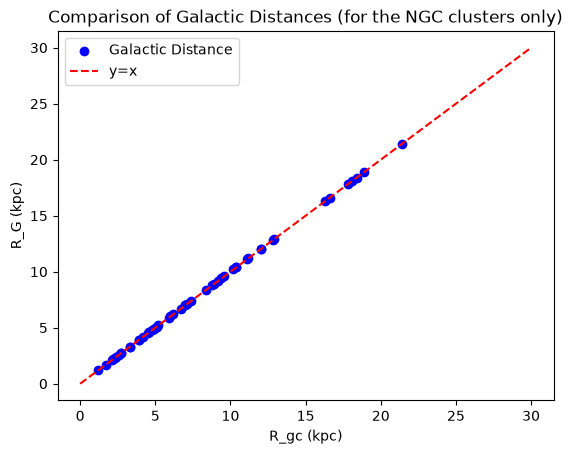

In [15]:
valid_R_G_data = harris_vdb_k21_merged[~harris_vdb_k21_merged['R_G'].isna()]
plt.scatter(valid_R_G_data['R_gc'], valid_R_G_data['R_G'], label='Galactic Distance', color='blue')
plt.plot([0, 30], [0, 30], color='red', linestyle='--', label='y=x')
plt.xlabel('R_gc (kpc)')
plt.ylabel('R_G (kpc)')
plt.title('Comparison of Galactic Distances (for the NGC clusters only)')
plt.legend()
plt.show()

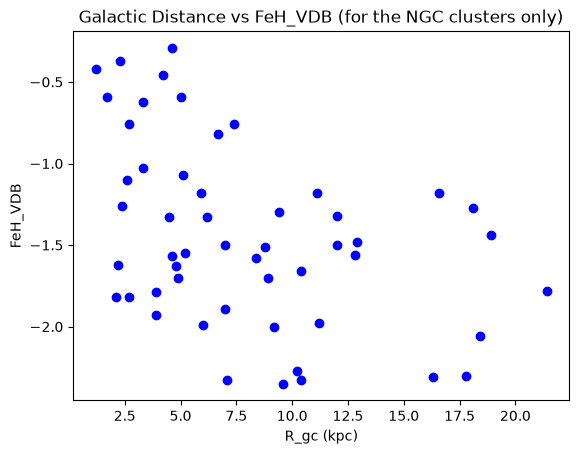

In [17]:
plt.scatter(harris_vdb_k21_merged['R_gc'], harris_vdb_k21_merged['FeH_VDB'], color='blue')
plt.xlabel('R_gc (kpc)')
plt.ylabel('FeH_VDB')
plt.title('Galactic Distance vs FeH_VDB (for the NGC clusters only)')
plt.show()

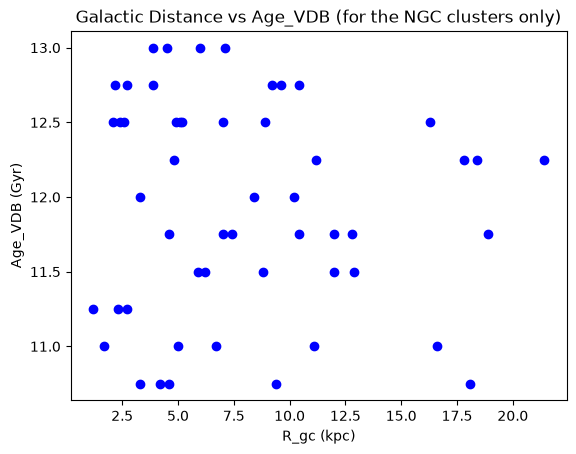

In [18]:
plt.scatter(harris_vdb_k21_merged['R_gc'], harris_vdb_k21_merged['Age_VDB'], color='blue')
plt.xlabel('R_gc (kpc)')
plt.ylabel('Age_VDB (Gyr)')
plt.title('Galactic Distance vs Age_VDB (for the NGC clusters only)')
plt.show()

Comparing Ages from VDB and Krause21 datasets

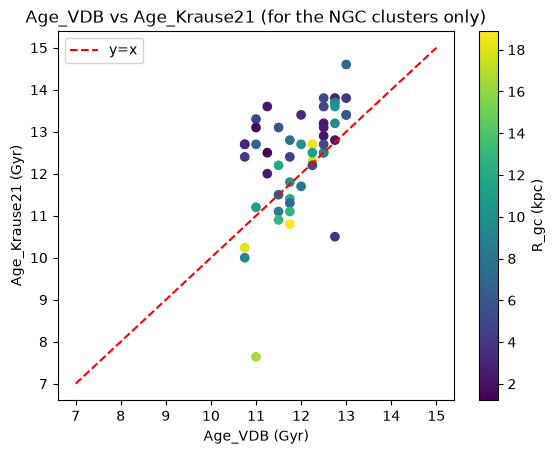

In [19]:
plt.scatter(harris_vdb_k21_merged['Age_VDB'], harris_vdb_k21_merged['Age_Krause21'], c=harris_vdb_k21_merged['R_gc'], cmap='viridis')
plt.colorbar(label='R_gc (kpc)')

plt.plot([7, 15], [7, 15], color='red', linestyle='--', label='y=x')
plt.legend()
plt.xlabel('Age_VDB (Gyr)')
plt.ylabel('Age_Krause21 (Gyr)')
plt.title('Age_VDB vs Age_Krause21 (for the NGC clusters only)')
plt.show()

Comparing Metallicity Values from VDB and Krause21

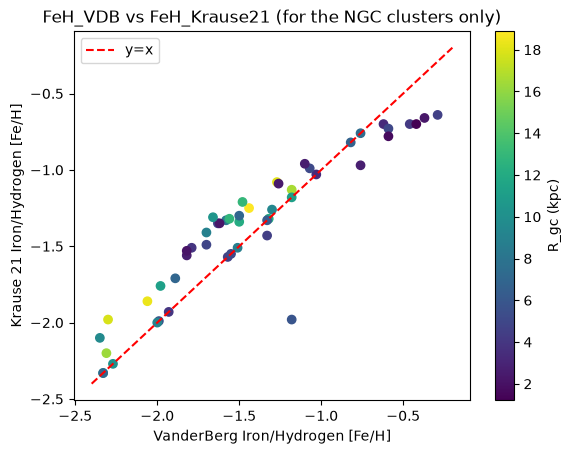

In [20]:
plt.scatter(harris_vdb_k21_merged['FeH_VDB'], harris_vdb_k21_merged['FeH_Krause21'], c=harris_vdb_k21_merged['R_gc'], cmap='viridis')
plt.colorbar(label='R_gc (kpc)')

plt.plot([-2.4, -0.2], [-2.4, -0.2], color='red', linestyle='--', label='y=x')
plt.legend()
plt.xlabel('VanderBerg Iron/Hydrogen [Fe/H]')
plt.ylabel('Krause 21 Iron/Hydrogen [Fe/H]')
plt.title('FeH_VDB vs FeH_Krause21 (for the NGC clusters only)')
plt.show()

Creating a Summary Table

In [21]:
summary = pd.DataFrame({
    'Table': ['harris_merged', 'VandenBerg Table 2', 'Krause21'],
    'Rows': [harris_merged.shape[0], VDB.shape[0], Krause21.shape[0]],
    'Unique IDs': [harris_merged['NGC_number'].nunique(), VDB['NGC_number'].nunique(), Krause21['NGC_number'].nunique()],
    'Unmatched IDs': [harris_merged['NGC_number'].isna().sum(), VDB['NGC_number'].isna().sum(), Krause21['NGC_number'].isna().sum()],
    'Duplicates': [harris_merged['NGC_number'].dropna().duplicated().sum(), VDB['NGC_number'].dropna().duplicated().sum(), Krause21['NGC_number'].dropna().duplicated().sum()]
})
display(summary)

,Table,Rows,Unique IDs,Unmatched IDs,Duplicates
0,harris_merged,157,104,53,0
1,VandenBerg Table 2,55,52,3,0
2,Krause21,61,58,3,0


Creating LookUp Table

In [24]:
# Checking the 3 unmatched IDs in VDB against the Harris table.
lookup = {'Arp21': 'Arp 2',             # probable
          'Ter8': 'Terzan 8', 
          'Pal12': 'Pal 12', 
          'Palomar12' : 'Pal 12', 
          'Ruprecht106' : 'Rup 106', 
          'Terzan7' : 'Terzan 7'}

vdb_name_only = VDB[VDB['NGC_number'].isna()].copy()
vdb_name_only['Harris_ID'] = vdb_name_only['Name'].map(lookup)

checked = pd.merge(vdb_name_only, harris_merged[['ID', 'R_gc']], left_on = 'Harris_ID', right_on = 'ID', how='left')
checked['difference'] = (checked['R_G'] - checked['R_gc']).abs()
display(checked[['Name', 'Harris_ID', 'R_G', 'R_gc', 'difference', 'Age_VDB', 'FeH_VDB']])


,Name,Harris_ID,R_G,R_gc,difference,Age_VDB,FeH_VDB
0,Arp21,Arp 2,21.4,21.4,0.0,12.0,-1.74
1,Pal12,Pal 12,15.8,15.8,0.0,9.0,-0.81
2,Ter8,Terzan 8,19.4,19.4,0.0,13.0,-2.34


In [25]:
# Checking the 3 unmatched IDs in Krause21 against the Harris table. 
krause_name_only = Krause21[Krause21['NGC_number'].isna()].copy()
krause_name_only['Harris_ID'] = krause_name_only['Object'].map(lookup)

checked = pd.merge(krause_name_only, harris_merged[['ID', 'R_gc']], left_on = 'Harris_ID', right_on = 'ID', how='left')
display(checked[['Object', 'Harris_ID', 'R_gc', 'Age_Krause21', 'FeH_Krause21']])


,Object,Harris_ID,R_gc,Age_Krause21,FeH_Krause21
0,Ruprecht106,Rup 106,18.5,12.0,-1.50
1,Terzan7,Terzan 7,15.6,7.4,-0.12
2,Palomar12,Pal 12,15.8,8.6,-0.81


Rebuilding the NGC label and creating the master table

In [26]:
def make_label(n):
    if pd.notna(n):
        return f'NGC {int(n)}'
    else:
        return None

VDB['Harris_ID'] = VDB['NGC_number'].apply(make_label)
Krause21['Harris_ID'] = Krause21['NGC_number'].apply(make_label)

VDB["Harris_ID"] = VDB["Harris_ID"].fillna(VDB["Name"].map(lookup))
Krause21["Harris_ID"] = Krause21["Harris_ID"].fillna(Krause21["Object"].map(lookup))

master = (harris_merged
    .merge(VDB[['Harris_ID', 'Age_VDB', 'FeH_VDB', 'Age_err', 'Method', 'R_G']], left_on='ID', right_on='Harris_ID', how='left')
    .drop(columns=['Harris_ID'])
    .merge(Krause21[['Harris_ID', 'Age_Krause21', 'FeH_Krause21', 'Mstar', 'rh']], left_on='ID', right_on='Harris_ID', how='left')
    .drop(columns=['Harris_ID'])
)

display(master)


,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number,Age_VDB,FeH_VDB,Age_err,Method,R_G,Age_Krause21,FeH_Krause21,Mstar,rh
0,1636-283,ESO452-SC11,16:39:25.45,-28:23:55.3,351.91,12.10,8.3,2.1,8.0,-1.1,1.7,NaN,NaN,NaN,NaN,NaN,1.00,0.50,0.50,20.75,2.50,8.07,7.87,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2MS-GC01,2MASS-GC01,18:08:21.81,-19:49:47,10.48,0.11,3.6,4.5,3.5,0.7,0.0,NaN,NaN,NaN,NaN,NaN,0.85,0.85,1.65,NaN,NaN,NaN,8.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2MS-GC02,2MASS-GC02,18:09:36.50,-20:46:44,9.79,-0.61,4.9,3.2,4.9,0.8,-0.1,-238.0,36.0,-227.4,NaN,NaN,0.95,0.55,0.55,NaN,NaN,NaN,7.72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AM 1,E 1,03:55:02.3,-49:36:55,258.34,-48.47,123.3,124.6,-16.5,-80.1,-92.3,116.0,20.0,101.3,NaN,NaN,1.36,0.17,0.41,23.62,0.03,8.96,9.61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AM 4,NaN,13:56:21.7,-27:10:03,320.28,33.51,32.2,27.8,20.7,-17.2,17.8,NaN,NaN,NaN,NaN,NaN,0.70,0.41,0.43,24.75,-0.05,8.42,8.32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,Terzan 8,NaN,19:41:44.41,-33:59:58.1,5.76,-24.56,26.3,19.4,23.8,2.4,-10.9,130.0,8.0,136.2,NaN,NaN,0.60,1.00,0.95,22.82,0.53,9.46,9.21,NaN,13.0,-2.34,0.38,V,19.4,NaN,NaN,NaN,NaN
153,Terzan 9,NaN,18:01:38.8,-26:50:23,3.61,-1.99,7.1,1.1,7.1,0.4,-0.2,59.0,10.0,68.1,NaN,NaN,2.50,0.03,0.78,23.21,4.42,4.99,8.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
154,Ton 2,Pismis 26,17:36:10.5,-38:33:12,350.80,-3.42,8.2,1.4,8.1,-1.3,-0.5,-184.4,2.2,-178.6,NaN,NaN,1.30,0.54,1.30,22.16,2.85,8.23,8.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
155,UKS 1,NaN,17:54:27.2,-24:08:43,5.13,0.76,7.8,0.7,7.8,0.7,0.1,57.0,6.0,66.7,NaN,NaN,2.10,0.15,NaN,25.52,4.41,7.26,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# ok, so here we check that the final table kept every Harris cluster exactly once.
assert len(master) == 157
assert master["ID"].is_unique
assert set(master["ID"]) == set(HarrisPartI["ID"])

# now we make sure to show how many clusters have ages from each source.
vdb_age_no = master["Age_VDB"].notna()
krause_age_no = master["Age_Krause21"].notna()

# now we print thr data to give us a holistic view of everything that worked out or not
print("Total clusters: ", len(master))
print("VanderBerg ages: ", vdb_age_no.sum())
print("Krause ages:", krause_age_no.sum())
print("Ages from both: ", (vdb_age_no & krause_age_no).sum())
print("Ages from neither: ", (~vdb_age_no & ~krause_age_no).sum())


# now we save the checked table for further analysis
master.to_csv("master.csv", index=False)
print("Saved master.csv")